In [72]:
#importing the libraries we need to use for data analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import MinMaxScaler

print("All good")

All good


In [73]:
#load the data set into the data frame(allows us to start exploring for potential data cleanups)
df = pd.read_csv("ai_productivity_dataset_final.csv")

# set display.max_columns to None so we can see all of them
pd.set_option('display.max_columns', None)

# first 5 rows to get a gist of what the data looks like
df.head()

,task_id,client,project_id,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,created_by,updated_at,task_status,workflow_stage,jira_ticket,legacy_ai_flag,content_version
0,T00000,Client_F,P038,mid,Content,report,junior,2,3.0,high,0,hourly,2025-11-20,2025-11-25,10.0,0,7.63,5.14,0.75,True,1,1,2.10,69.93,498.11,346.17,151.94,user_096,2025-11-28,review,finalized,JIRA-49014,true,v1
1,T00001,Client_H,P028,low,Paid Media,release,junior,1,2.0,medium,0,fixed,2026-01-24,2026-01-26,7.0,0,9.52,8.22,0.12,False,1,1,4.48,82.79,847.01,343.18,503.83,user_058,2026-01-26,delivered,client_review,JIRA-84793,false,v1
2,T00002,Client_D,P009,low,Design,dev,junior,3,4.0,medium,0,fixed,2025-09-16,2025-09-23,5.0,1,8.45,6.15,0.37,True,2,0,2.71,76.40,1374.07,365.02,1009.05,user_074,2025-09-17,in_progress,qa,JIRA-42485,true,v2
3,T00003,Client_E,P023,mid,Content,design,mid,3,2.0,low,0,hourly,2025-11-06,2025-11-09,3.0,0,28.35,24.22,0.07,False,4,1,0.00,NaN,2379.11,1514.73,864.38,user_011,2025-11-12,in_progress,briefing,JIRA-53111,false,v1
4,T00004,Client_C,P014,low,Design,article,senior,2,5.0,low,0,fixed,2026-05-02,2026-05-06,7.0,0,5.93,4.44,0.20,True,2,2,0.84,NaN,709.95,335.27,374.68,user_007,2026-05-09,review,execution,JIRA-86006,true,v2


In [74]:
# checking the column names to see what variables we are working with
print("Columns:", df.columns)

# getting general information about the dataset to check for missing values
df.info()

#rows and columns
print("Shape:", df.shape)

Columns: Index(['task_id', 'client', 'project_id', 'client_tier', 'team', 'task_type',
       'seniority', 'task_complexity_score', 'brief_quality_score',
       'deadline_pressure', 'scope_change_flag', 'pricing_model', 'created_at',
       'delivered_at', 'sla_days', 'sla_breach', 'hours_spent',
       'billable_hours', 'ai_usage_pct', 'ai_assisted', 'revisions', 'errors',
       'rework_hours', 'outcome_score', 'revenue', 'cost', 'profit',
       'created_by', 'updated_at', 'task_status', 'workflow_stage',
       'jira_ticket', 'legacy_ai_flag', 'content_version'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 3248 entries, 0 to 3247
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   task_id                3248 non-null   str    
 1   client                 3248 non-null   str    
 2   project_id             3248 non-null   str    
 3   client_tier            3248 non-null   str   

In [75]:
#so we don't accidentally change the original dataset
df_clean = df.copy()

In [76]:
#takes out negative billable hours in the data
df_clean = df_clean[df_clean['billable_hours'] >= 0]

In [77]:
#remove columns with no useful information
cols_to_drop = ['task_id', 'client', 'project_id', 'created_by', 'updated_at', 'jira_ticket', 'legacy_ai_flag']
df_clean = df_clean.drop(columns=cols_to_drop)

In [78]:
# check for improperly labeled values
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(), 
      sep='\n\n')

team
Content       782
Media         754
Design        737
SEO           724
seo            29
media          25
content        21
SEO            18
design         18
DESIGN         12
Contennt        8
Paid Media      7
MEDIA           7
Desgn           5
CONTENT         2
Name: count, dtype: int64

client_tier
mid     1468
low      851
high     830
Name: count, dtype: int64

task_type
design            441
ticket            441
ad                441
report            437
article           428
dev               420
release           409
article_task       15
relese             10
design_task        10
ad_task             9
ticket_task         9
Report              8
release_task        8
Ticket              7
report_task         7
Design              7
Ad                  6
development         5
creative            5
dev_task            4
repport             4
paid_ad             4
artcle              3
support_ticket      3
Release             3
blog_article        2
DEV             

In [79]:
# set all string values to lowercase and rename those labeled incorrectly
for col in df_clean.select_dtypes(include=['object', 'string']).columns:
    df_clean[col] = df_clean[col].str.lower()

df_clean['team'] = df_clean['team'].replace({
    'seo ': 'seo',
    'contennt': 'content',
    'desgn': 'design',
    'paid media': 'media'
})

df_clean['task_type'] = df_clean['task_type'].replace({
    'article_task': 'task',
    'ad_task': 'ad',
    'relese': 'release',
    'ticket_task': 'ticket',
    'design_task': 'design',
    'release_task': 'release',
    'report_task': 'report',
    'development': 'dev',
    'creative': 'design',
    'dev_task': 'dev',
    'repport': 'report',
    'paid_ad': 'ad',
    'artcle': 'article',
    'support_ticket': 'ticket',
    'blog_article': 'article'
})

In [80]:
# check value counts again to make sure all values were handled properly
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(),
      sep='\n\n')

team
content    813
media      793
design     772
seo        771
Name: count, dtype: int64

client_tier
mid     1468
low      851
high     830
Name: count, dtype: int64

task_type
design     463
ticket     460
ad         460
report     456
article    434
dev        431
release    430
task        15
Name: count, dtype: int64

seniority
mid       1249
junior    1163
senior     737
Name: count, dtype: int64

deadline_pressure
medium    1430
low        895
high       824
Name: count, dtype: int64

pricing_model
hourly         1513
fixed          1184
value_based     452
Name: count, dtype: int64

task_status
in_progress    1091
review          840
delivered       748
draft           180
blocked         147
archived        143
Name: count, dtype: int64

workflow_stage
qa               667
client_review    641
finalized        621
briefing         621
execution        599
Name: count, dtype: int64


In [81]:
# drop 15 tasks labeled as "task"
df_clean = df_clean[df_clean['task_type'] != 'task']

In [82]:
#summary of all columns(numerical & categorical);to understand general patterns in the dataa
df_clean.describe(include='all')

,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,task_status,workflow_stage,content_version
count,3134,3134,3134,3134,3134.000000,3068.000000,3134,3134.000000,3134,3134,3100,3100.000000,3134.000000,3134.000000,3134.000000,2994.000000,3134,3134.000000,3134.000000,3069.000000,3006.000000,3134.000000,3134.000000,3134.000000,3134,3134,3134
unique,3,4,7,3,NaN,NaN,3,NaN,3,330,335,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,5,5
top,mid,content,design,mid,NaN,NaN,medium,NaN,hourly,2026-03-27,2026-01-18,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,in_progress,qa,v1
freq,1460,808,463,1247,NaN,NaN,1423,NaN,1507,20,18,NaN,NaN,NaN,NaN,NaN,2468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1087,662,894
mean,NaN,NaN,NaN,NaN,2.866305,3.179922,NaN,0.138800,NaN,NaN,NaN,5.021290,0.398851,13.059274,8.491334,0.361637,NaN,2.994576,1.018188,2.441302,68.808526,1122.294992,770.429942,351.865049,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,1.197265,1.210847,NaN,0.345793,NaN,NaN,NaN,2.519533,0.489740,11.661173,4.749082,0.199394,NaN,1.800708,1.048758,2.940878,12.641892,845.594222,585.102199,891.359873,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,2.000000,0.000000,0.040000,0.870000,0.000000,NaN,0.000000,0.000000,0.000000,9.000000,45.000000,77.850000,-8510.549511,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.000000,2.000000,NaN,0.000000,NaN,NaN,NaN,3.000000,0.000000,7.910000,5.120000,0.200000,NaN,2.000000,0.000000,1.110000,60.787500,646.427500,438.495000,-2.535000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,3.000000,3.000000,NaN,0.000000,NaN,NaN,NaN,5.000000,0.000000,11.090000,7.580000,0.340000,NaN,3.000000,1.000000,1.810000,69.330000,966.315000,646.665000,255.600000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,4.000000,4.000000,NaN,0.000000,NaN,NaN,NaN,7.000000,1.000000,15.360000,10.717500,0.500000,NaN,4.000000,2.000000,2.950000,77.620000,1369.895000,943.925000,594.122500,NaN,NaN,NaN


# Missing values

Because brief_quality_score, sla_days, billable_hours, ai_usage_pct, rework_hours, and outcome_score are all numeric features we can easily impute them using iterative imputation. We can assume missing values depend on multiple features, therefore this approach is justifiable. Unfortunately, delivered_at can't be imputed, thus these rows will be removed.


client_tier                0
team                       0
task_type                  0
seniority                  0
task_complexity_score      0
brief_quality_score       66
deadline_pressure          0
scope_change_flag          0
pricing_model              0
created_at                 0
delivered_at              34
sla_days                  34
sla_breach                 0
hours_spent                0
billable_hours             0
ai_usage_pct             140
ai_assisted                0
revisions                  0
errors                     0
rework_hours              65
outcome_score            128
revenue                    0
cost                       0
profit                     0
task_status                0
workflow_stage             0
content_version            0
dtype: int64


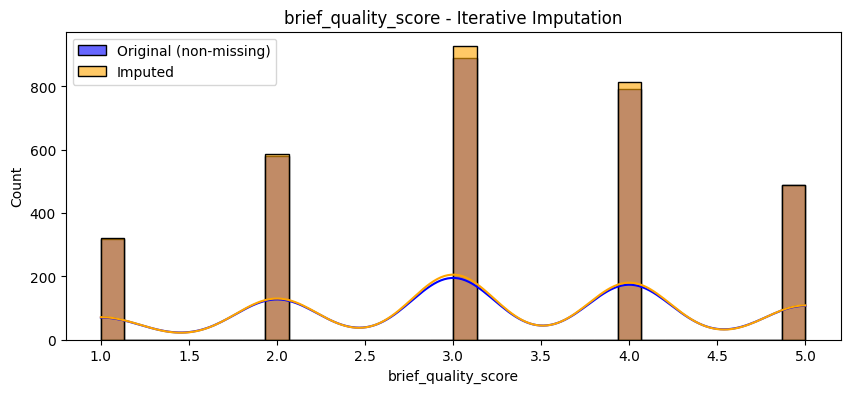

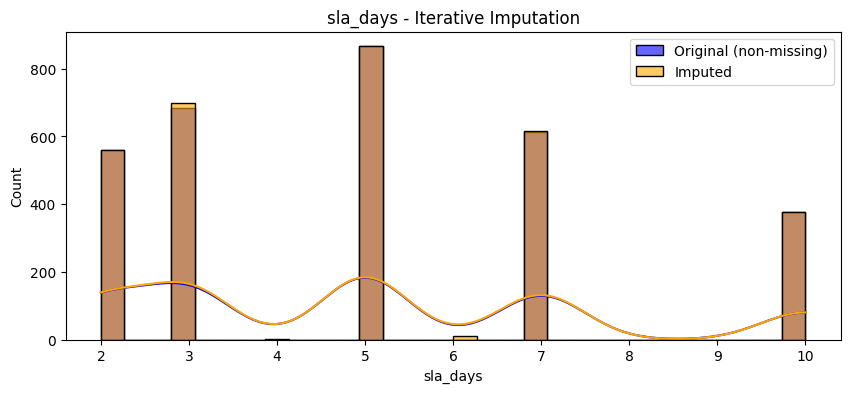

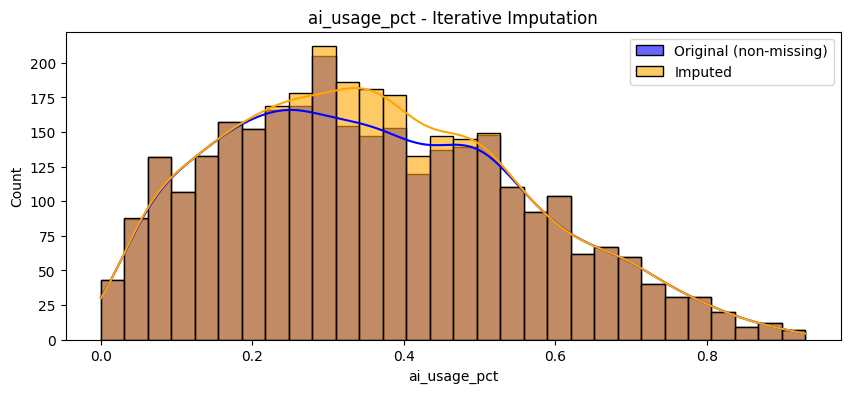

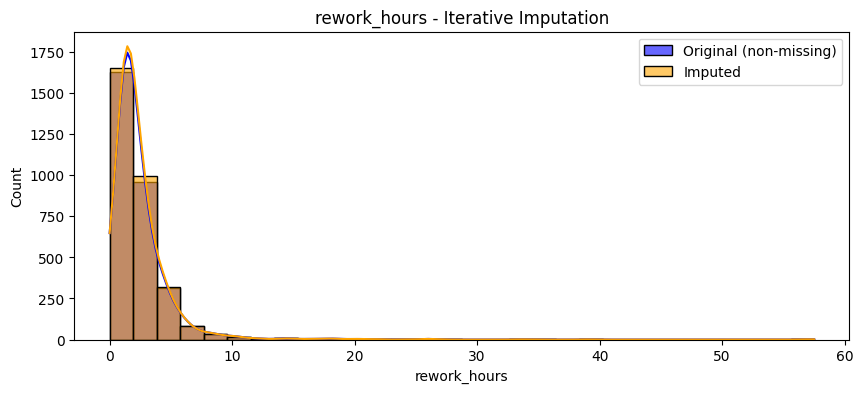

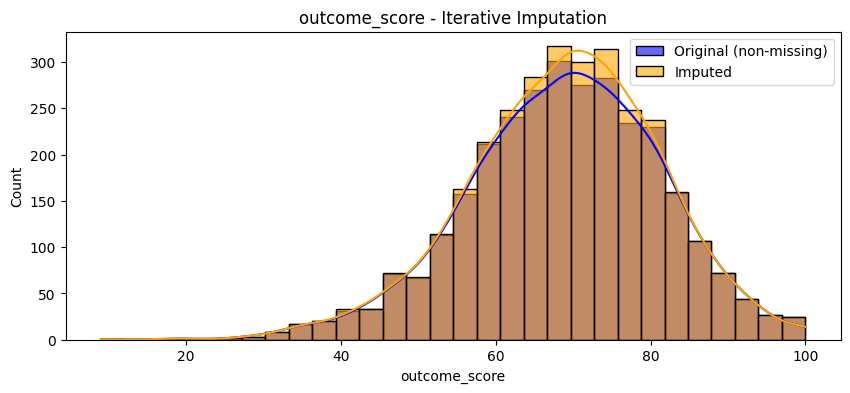

In [83]:
print(df_clean.isnull().sum())

# iterative imputation
df_numerical = df_clean.select_dtypes(include=['number'])

iter_imp = IterativeImputer(random_state=42)
df_iter = pd.DataFrame(iter_imp.fit_transform(df_numerical), columns=df_numerical.columns)

# round brief_quality_score and sla_days such that they are integers
df_iter['brief_quality_score'] = df_iter['brief_quality_score'].round()
df_iter['sla_days'] = df_iter['sla_days'].round()

# remove negative billable_hours
df_iter['billable_hours'] = df_iter['billable_hours'].clip(lower=0)

# plot the orignal vs. imputed distributions of numerical features
def plot_imputation_comparison(original, imputed, title):
    plt.figure(figsize=(10, 4))
    sns.histplot(original.dropna(), kde=True, color='blue', label='Original (non-missing)', bins=30, alpha=0.6)
    sns.histplot(imputed, kde=True, color='orange', label='Imputed', bins=30, alpha=0.6)
    plt.title(title)
    plt.legend()
    plt.show()

for col in df_numerical.columns:
    if df_numerical[col].isnull().any():
        plot_imputation_comparison(df_numerical[col], df_iter[col], f"{col} - Iterative Imputation")

# merge the imputed data back into the original df
df_clean[df_numerical.columns] = df_iter

# drop rows with missing delivered_at values
df_clean = df_clean.dropna()

In [84]:
#checking final shape after cleaning
print("Final shape:", df_clean.shape)
#make sure there arnet missing values left
print(df_clean.isnull().sum())
#confirm no remaining duplicate rows
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Final shape: (2989, 27)
client_tier              0
team                     0
task_type                0
seniority                0
task_complexity_score    0
brief_quality_score      0
deadline_pressure        0
scope_change_flag        0
pricing_model            0
created_at               0
delivered_at             0
sla_days                 0
sla_breach               0
hours_spent              0
billable_hours           0
ai_usage_pct             0
ai_assisted              0
revisions                0
errors                   0
rework_hours             0
outcome_score            0
revenue                  0
cost                     0
profit                   0
task_status              0
workflow_stage           0
content_version          0
dtype: int64
Duplicate rows after cleaning: 0


# EDA


## Heatmap

The heatmap reveals interesting relationships: negative relationship between ai_usage_pct and sla_breach, billable_hours, and cost.

Other interesting relationships include: negative correlations between outcome_score and task_complexity_score, revisions, errors and rework_hours.

No strong trends emerge regarding revenue, cost or profit.


<Axes: >

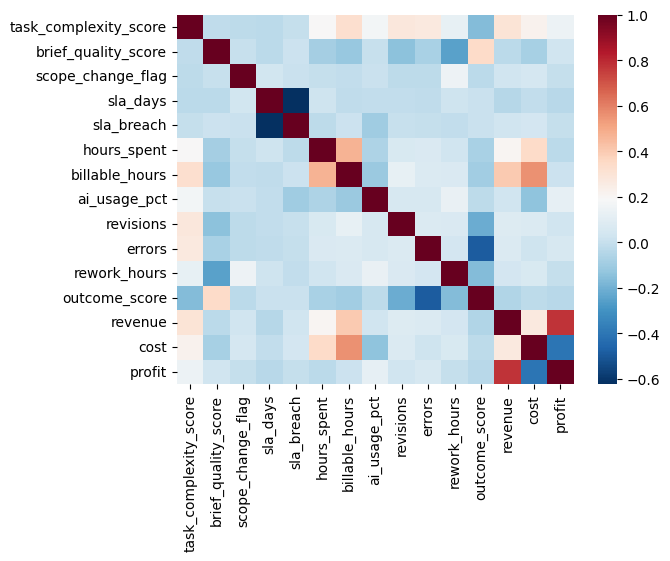

In [85]:
corr = df_numerical.corr()

sns.heatmap(corr, cmap = 'RdBu_r')

## Regression


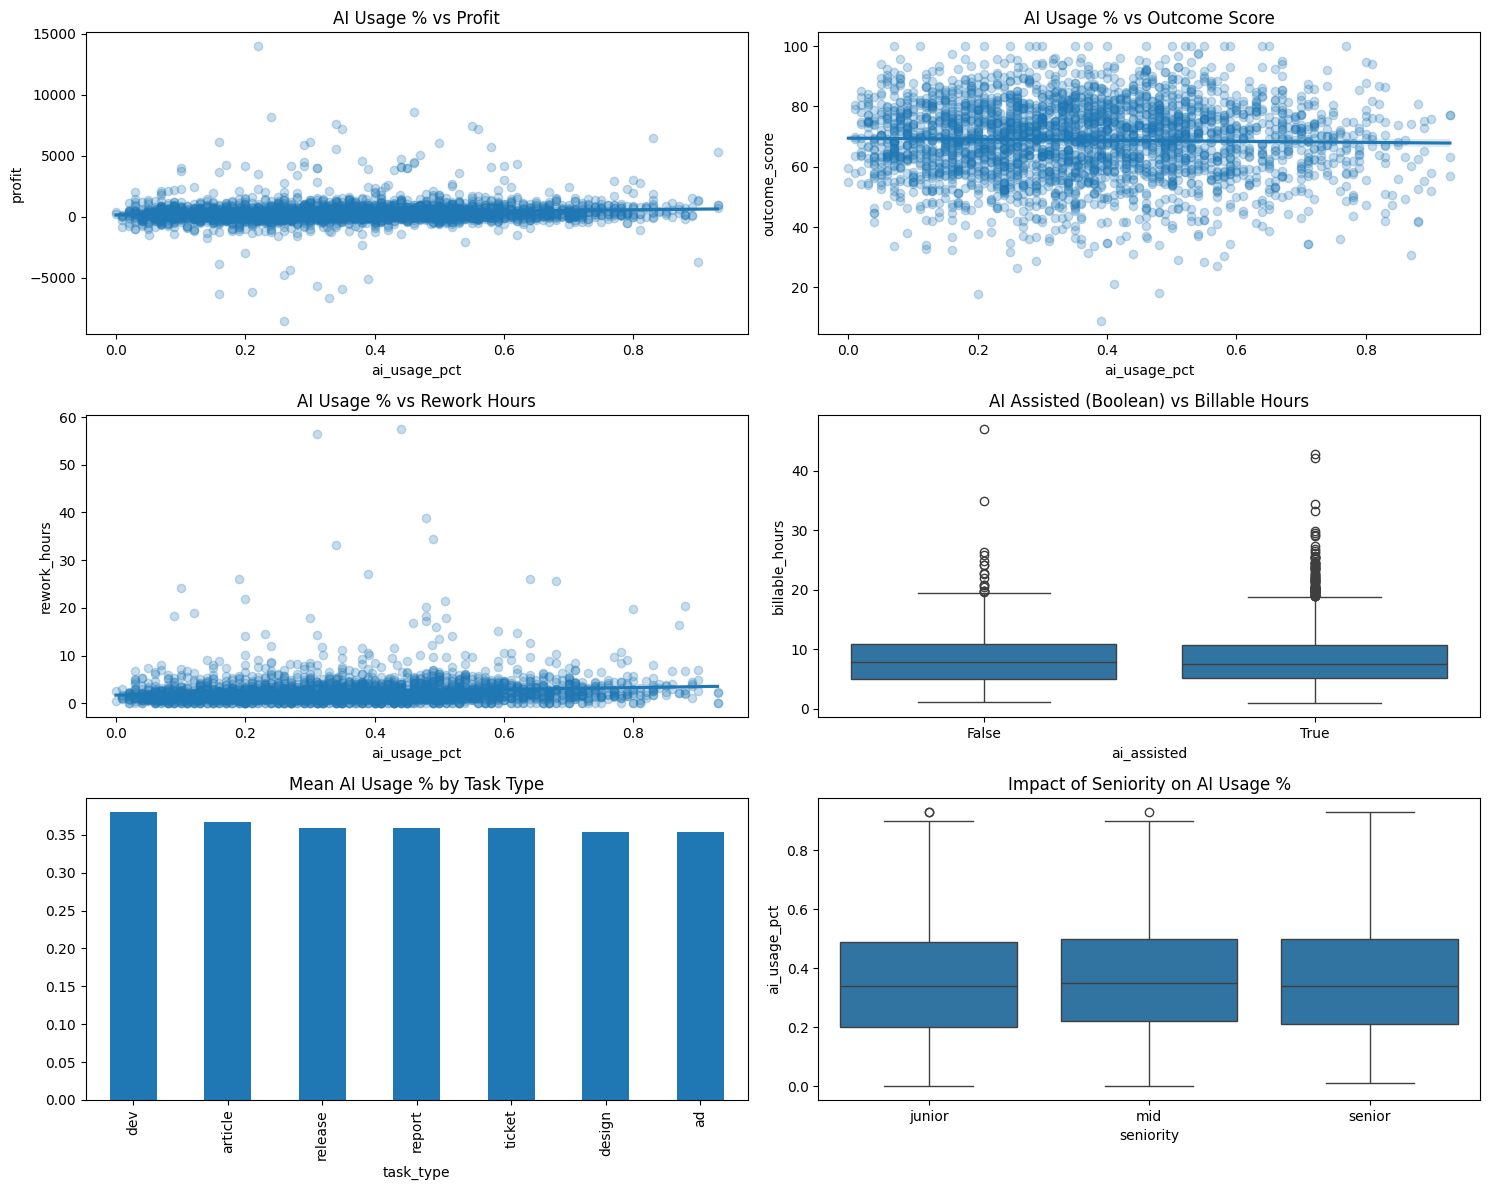

In [86]:
plt.figure(figsize=(15, 12))

plt.subplot(3, 2, 1)
sns.regplot(data=df_clean, x='ai_usage_pct', y='profit', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Profit')

plt.subplot(3, 2, 2)
sns.regplot(data=df_clean, x='ai_usage_pct', y='outcome_score', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Outcome Score')

plt.subplot(3, 2, 3)
sns.regplot(data=df_clean, x='ai_usage_pct', y='rework_hours', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Rework Hours')

plt.subplot(3, 2, 4)
sns.boxplot(data=df_clean, x='ai_assisted', y='billable_hours')
plt.title('AI Assisted (Boolean) vs Billable Hours')

plt.subplot(3, 2, 5)
df_clean.groupby('task_type')['ai_usage_pct'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Mean AI Usage % by Task Type')

plt.subplot(3, 2, 6)
sns.boxplot(data=df_clean, x='seniority', y='ai_usage_pct', order=['junior', 'mid', 'senior'])
plt.title('Impact of Seniority on AI Usage %')

plt.tight_layout()

# Analysis


### 1. Where is value created?

Identify tasks where AI produces a measurable and positive impact.


In [87]:
# summary table comparing the mean of efficiency metrics given AI vs Non-AI per task
metrics = ['profit', 'outcome_score', 'hours_spent']
impact_df = df_clean.groupby(['task_type', 'ai_assisted'])[metrics].mean().unstack()

# individual lift % for each metric
impact_df['profit_lift'] = (impact_df['profit'][True] - impact_df['profit'][False]) / impact_df['profit'][False]
impact_df['quality_lift'] = (impact_df['outcome_score'][True] - impact_df['outcome_score'][False]) / impact_df['outcome_score'][False]
impact_df['time_savings'] = (impact_df['hours_spent'][False] - impact_df['hours_spent'][True]) / df_clean['hours_spent'].mean()

print(impact_df[['profit_lift', 'quality_lift', 'time_savings']])

            profit_lift quality_lift time_savings
ai_assisted                                      
task_type                                        
ad            -0.375874    -0.009460    -0.161000
article        3.749073     0.037502     0.093731
design        -0.062679    -0.012216    -0.077176
dev            0.031056     0.002695    -0.064092
release        0.012016    -0.015214     0.016234
report        -0.493896    -0.014723    -0.048165
ticket        -0.098910    -0.042966     0.026391


Text(0, 0.5, 'Normalized Value Score')

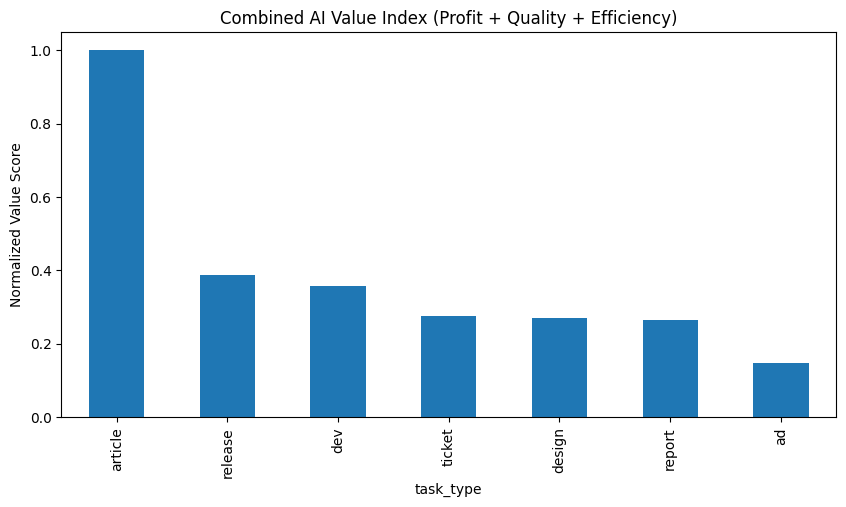

In [88]:
lift_cols = ['profit_lift', 'quality_lift', 'time_savings']
lifts = impact_df[lift_cols]

# normalize all lifts to a 0-1 scale so they carry equal weight
scaler = MinMaxScaler()
normalized_lifts = pd.DataFrame(
    scaler.fit_transform(lifts), 
    index=lifts.index, 
    columns=lift_cols
)

# combined (mean) AI value score
impact_df['AI_Value_Index'] = normalized_lifts.mean(axis=1)

impact_df['AI_Value_Index'].sort_values(ascending=False).plot(kind='bar', figsize=(10,5))
plt.title('Combined AI Value Index (Profit + Quality + Efficiency)')
plt.ylabel('Normalized Value Score')

### 2. Where are losses incurred?

Track losses: rework, declining quality, hidden costs


In [89]:
#hidden cost = hours spent but not billed
df_clean['extra_hours'] = df_clean['hours_spent'] - df_clean['billable_hours']

In [90]:
#summary table comparing mean loss metrics for AI vs Non-AI per task
loss_metrics = ['rework_hours', 'extra_hours', 'outcome_score']
loss_df = df_clean.groupby(['task_type', 'ai_assisted'])[loss_metrics].mean().unstack()

#individual loss measures
loss_df['rework_increase'] = (loss_df['rework_hours'][True] - loss_df['rework_hours'][False]) / loss_df['rework_hours'][False]
loss_df['extra_hours_increase'] = (loss_df['extra_hours'][True] - loss_df['extra_hours'][False]) / loss_df['extra_hours'][False]
loss_df['quality_decline'] = (loss_df['outcome_score'][False] - loss_df['outcome_score'][True]) / loss_df['outcome_score'][False]

print(loss_df[['rework_increase', 'extra_hours_increase', 'quality_decline']])

            rework_increase extra_hours_increase quality_decline
ai_assisted                                                     
task_type                                                       
ad                 0.304048             0.634702        0.009460
article            0.016095            -0.029092       -0.037502
design             0.052526             0.248035        0.012216
dev                0.201120             0.020703       -0.002695
release            0.203916            -0.044388        0.015214
report             0.091722             0.148788        0.014723
ticket             0.264731            -0.096928        0.042966


In [91]:
loss_cols = ['rework_increase', 'extra_hours_increase', 'quality_decline']
losses = loss_df[loss_cols].copy()

In [92]:
#cleans up inf values before scaling because percentages won't calculate properly if the demoninator is 0
losses = losses.replace([np.inf, -np.inf], np.nan).fillna(0)

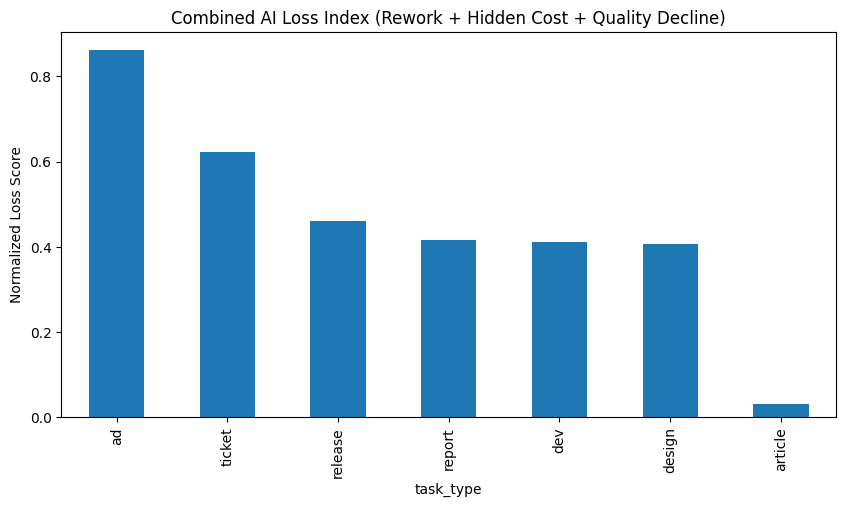

In [93]:
#normalize all loss metrics to a 0-1 scale so they carry equal weight
scaler = MinMaxScaler()
normalized_losses = pd.DataFrame(
    scaler.fit_transform(losses),
    index=losses.index,
    columns=loss_cols
)

#combined mean AI loss score
loss_df['AI_Loss_Index'] = normalized_losses.mean(axis=1)

loss_df['AI_Loss_Index'].sort_values(ascending=False).plot(kind='bar', figsize=(10,5))
plt.title('Combined AI Loss Index (Rework + Hidden Cost + Quality Decline)')
plt.ylabel('Normalized Loss Score')
plt.show()

ai_bin
Medium    1363
Low       1264
High       362
Name: count, dtype: int64
count    2989.000000
mean        0.361441
std         0.195314
min         0.000000
25%         0.210000
50%         0.350000
75%         0.500000
max         0.930000
Name: ai_usage_pct, dtype: float64


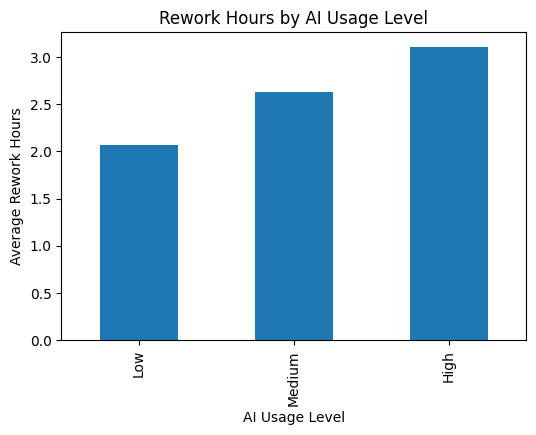

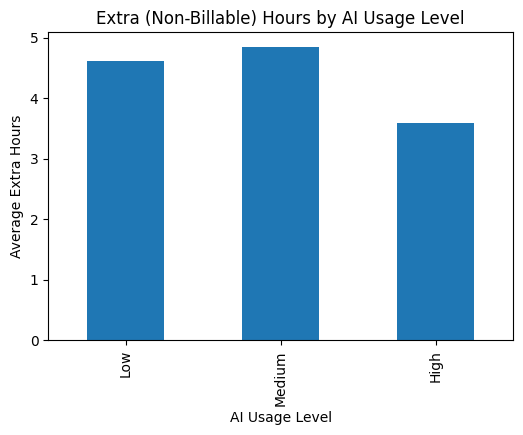

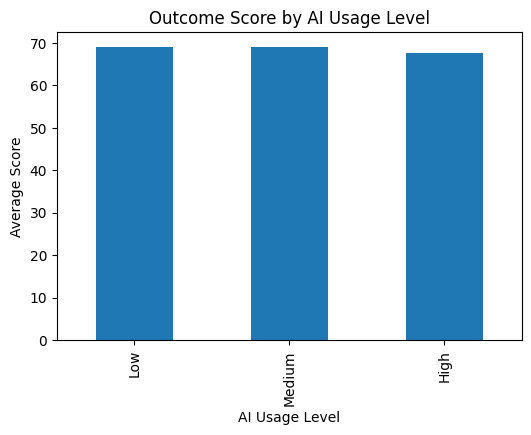

In [94]:
#creates bins to view levels of AI usage
df_clean['ai_bin'] = pd.cut(
    df_clean['ai_usage_pct'],
    bins=[0, 0.3, 0.6, 1],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

#checking num of observations
print(df_clean['ai_bin'].value_counts())
print(df_clean['ai_usage_pct'].describe())

#rework by AI usage level
df_clean.groupby('ai_bin')['rework_hours'].mean().plot(kind='bar', figsize=(6,4))
plt.title('Rework Hours by AI Usage Level')
plt.ylabel('Average Rework Hours')
plt.xlabel('AI Usage Level')
plt.show()

#extra (non-billable) hours by AI usage level
df_clean.groupby('ai_bin')['extra_hours'].mean().plot(kind='bar', figsize=(6,4))
plt.title('Extra (Non-Billable) Hours by AI Usage Level')
plt.ylabel('Average Extra Hours')
plt.xlabel('AI Usage Level')
plt.show()

#outcome score by AI usage level
df_clean.groupby('ai_bin')['outcome_score'].mean().plot(kind='bar', figsize=(6,4))
plt.title('Outcome Score by AI Usage Level')
plt.ylabel('Average Score')
plt.xlabel('AI Usage Level')
plt.show()

### 3. AI -> quality of just speed?


In [95]:
#compare speed vs quality for AI and for non-AI
sq_metrics = ['hours_spent', 'outcome_score', 'rework_hours']
sq_df = df_clean.groupby('ai_assisted')[sq_metrics].mean()
print(sq_df)

#hours_spent is lower -> faster
#outcome_score is higher -> better quality
#rework_hours is lower -> better quality

             hours_spent  outcome_score  rework_hours
ai_assisted                                          
False          12.771370      69.325670      2.184590
True           13.173901      68.716148      2.525179


In [96]:

#calculating percent change for time, quality, and rework between AI-assisted and non-AI-assisted tasks
sq_change = {
    'time_change': (sq_df.loc[False, 'hours_spent'] - sq_df.loc[True, 'hours_spent']) / sq_df.loc[False, 'hours_spent'],
    'quality_change': (sq_df.loc[True, 'outcome_score'] - sq_df.loc[False, 'outcome_score']) / sq_df.loc[False, 'outcome_score'],
    'rework_change': (sq_df.loc[True, 'rework_hours'] - sq_df.loc[False, 'rework_hours']) / sq_df.loc[False, 'rework_hours']
}

sq_change = pd.DataFrame(sq_change, index=['AI vs Non-AI'])

print(sq_change)

              time_change  quality_change  rework_change
AI vs Non-AI    -0.031518       -0.008792       0.155906


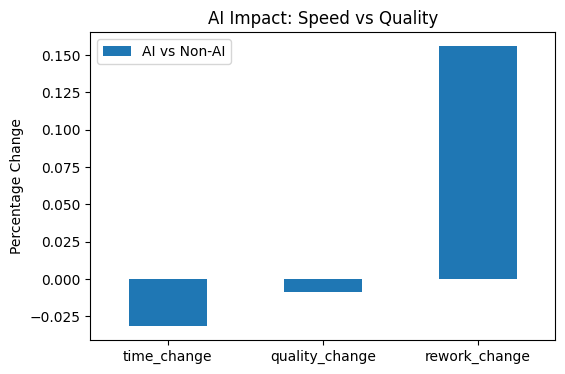

In [97]:
#plots the values
sq_change.T.plot(kind='bar', figsize=(6,4))
plt.title('AI Impact: Speed vs Quality')
plt.ylabel('Percentage Change')
plt.xticks(rotation=0)
plt.show()


# time change -> negative (AI is slower)
# quality change -> negative (AI is lower quality)
# rework change -> positive (AI has more errors)